# Clasificador bayesiano: Naive Bayes
## Proyecto final de Ciencia de Datos · *Bank Marketing* (UCI)

**Instructor:** M. en C. Benito Samuel López Razo · **Autores:** _(escribe aquí tu nombre y el de tu equipo)_ · **Semilla global:** 42

Este notebook vive en la carpeta `modelos/` y es **independiente** de los demás. Todo lo compartido (carga de datos, división, validación cruzada y funciones de evaluación) está en `utils_proyecto.py`, para que todos los modelos se comparen bajo las mismas reglas (las reglas están en la sección 1 de `01_regresion_logistica.ipynb`).

El PDF pide **Naive Bayes en la variante adecuada para los datos, explicando qué supuestos hace y si el dataset los cumple**. Por eso este notebook no entrena una sola variante a ciegas: primero revisa los supuestos con los datos, luego compara tres variantes con validación cruzada y se queda con la mejor.

**Índice**

1. Carga de datos
2. Supuestos de Naive Bayes y qué tan bien los cumple este dataset
3. Variantes e hiperparámetros (espacio de búsqueda)
4. Búsqueda en malla con validación cruzada
5. Evaluación de la variante elegida en el conjunto de prueba
6. Variabilidad entre folds
7. Experimento: ¿cuánto daña la redundancia entre variables?
8. Calibración de las probabilidades
9. Interpretación

## 1. Carga de datos

La celda siguiente importa lo necesario y carga los datos con `utils_proyecto.py`. **La tabla de control debe dar 31,647 / 6,782 / 6,782 filas y 11.70 % de `yes`** en cada conjunto, igual que la sección 6 de la Parte 1.

`N_JOBS = -1` usa todos los núcleos del procesador; si tu computadora se pone lenta, cámbialo a `2`.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, skew
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OrdinalEncoder

import utils_proyecto as up

SEED = up.SEED
N_JOBS = -1
d = up.cargar_datos()

display(up.resumen_datos(d))

,filas,% clase 'yes'
train,31647,11.70
validation,6782,11.69
test,6782,11.69


## 2. Supuestos de Naive Bayes y qué tan bien los cumple este dataset

Naive Bayes aplica el teorema de Bayes y calcula, para cada cliente, qué tan probable es que contrate multiplicando la evidencia de cada variable por separado. Para poder hacerlo asume:

1. **Independencia condicional:** dada la clase (`yes` / `no`), las variables son independientes entre sí. Si dos variables dicen "lo mismo", Naive Bayes cuenta esa evidencia **dos veces** y exagera la confianza.
2. **Forma de la distribución de cada variable dada la clase:**
   - `GaussianNB` supone que cada variable es **normal** (campana de Gauss).
   - `CategoricalNB` supone que cada variable es **categórica** y estima la frecuencia de cada categoría por clase (no exige forma normal, pero para usar numéricas hay que discretizarlas).

Los datos de Bank Marketing mezclan 6 numéricas, 9 categóricas (que al aplicar *one-hot* se vuelven columnas 0/1) y 1 binaria. Se revisa cada supuesto con los datos de **entrenamiento**.

### 2.1 Independencia entre variables numéricas (dentro de cada clase)

Correlación de Spearman (apropiada para variables con colas largas) entre cada par de numéricas, calculada por separado en cada clase. Si fueran independientes, todas serían cercanas a 0.

In [2]:
num_train = d.X_train[d.cols_num].assign(y=d.y_train)

filas = []
for a, b in combinations(d.cols_num, 2):
    fila = {"par": f"{a} – {b}"}
    for clase, nombre in [(0, "no"), (1, "yes")]:
        sub = num_train[num_train["y"] == clase]
        fila[f"r (clase {nombre})"] = sub[a].corr(sub[b], method="spearman")
    filas.append(fila)

corr_num = pd.DataFrame(filas)
corr_num["|r| máx"] = corr_num[["r (clase no)", "r (clase yes)"]].abs().max(axis=1)
corr_num = corr_num.sort_values("|r| máx", ascending=False).reset_index(drop=True)

display(corr_num.head(6).round(3))
up.guardar_tabla(corr_num.round(4), "tabla_nb_dependencia_numericas")

,par,r (clase no),r (clase yes),|r| máx
0,pdays – previous,0.990,0.929,0.990
1,day – campaign,0.153,0.047,0.153
2,age – balance,0.091,0.144,0.144
3,campaign – pdays,-0.100,-0.103,0.103
4,day – pdays,-0.102,-0.024,0.102
5,campaign – previous,-0.096,-0.101,0.101


Tabla guardada: resultados/tabla_nb_dependencia_numericas.csv


### 2.2 Independencia entre variables categóricas (dentro de cada clase)

V de Cramér entre cada par de variables categóricas o binarias, calculada por separado en cada clase (0 = independientes, 1 = una determina a la otra). Se muestran los pares más dependientes.

In [3]:
def v_seguro(x, y):
    # V de Cramér; devuelve NaN si la tabla no permite calcularla
    try:
        return up.cramers_v(x, y)[0]
    except ValueError:
        return np.nan


cols_discretas = d.cols_cat + d.cols_bin
filas = []
for a, b in combinations(cols_discretas, 2):
    fila = {"par": f"{a} – {b}"}
    for clase, nombre in [(0, "no"), (1, "yes")]:
        m = d.y_train == clase
        fila[f"V (clase {nombre})"] = v_seguro(d.X_train.loc[m, a], d.X_train.loc[m, b])
    filas.append(fila)

v_pares = pd.DataFrame(filas)
v_pares["V máx"] = v_pares[["V (clase no)", "V (clase yes)"]].max(axis=1)
v_pares = v_pares.sort_values("V máx", ascending=False).reset_index(drop=True)

display(v_pares.head(8).round(3))
up.guardar_tabla(v_pares.round(4), "tabla_nb_dependencia_categoricas")

,par,V (clase no),V (clase yes),V máx
0,poutcome – pdays_contactado,1.000,0.999,1.000
1,contact – month,0.527,0.342,0.527
2,housing – month,0.519,0.385,0.519
3,job – education,0.460,0.457,0.460
4,month – pdays_contactado,0.342,0.204,0.342
5,job – housing,0.268,0.317,0.317
6,contact – pdays_contactado,0.285,0.240,0.285
7,job – marital,0.193,0.275,0.275


Tabla guardada: resultados/tabla_nb_dependencia_categoricas.csv


### 2.3 Forma de las distribuciones numéricas

`GaussianNB` espera variables con forma de campana. Dos medidas lo resumen:

- **Asimetría (skewness):** 0 en una normal; valores grandes indican cola larga hacia un lado.
- **Curtosis en exceso:** 0 en una normal; valores grandes indican colas muy pesadas.

Se comparan las numéricas **solo estandarizadas** contra las transformadas con **Yeo-Johnson** (que intenta volverlas más simétricas). Las columnas *one-hot* son binarias (0/1), así que **nunca** pueden ser normales.

,asimetría (estandarizada),asimetría (Yeo-Johnson),curtosis exceso (estandarizada),curtosis exceso (Yeo-Johnson)
age,0.68,0.01,0.33,-0.53
balance,8.32,1.43,133.40,67.72
day,0.09,-0.16,-1.05,-0.99
campaign,4.91,0.23,38.89,-1.21
pdays,2.61,1.65,6.83,0.73
previous,7.67,1.65,103.50,0.73


Tabla guardada: resultados/tabla_nb_forma_distribuciones.csv
Columnas tras el preprocesamiento: 48 (de las cuales 6 son numéricas y 42 son binarias 0/1)


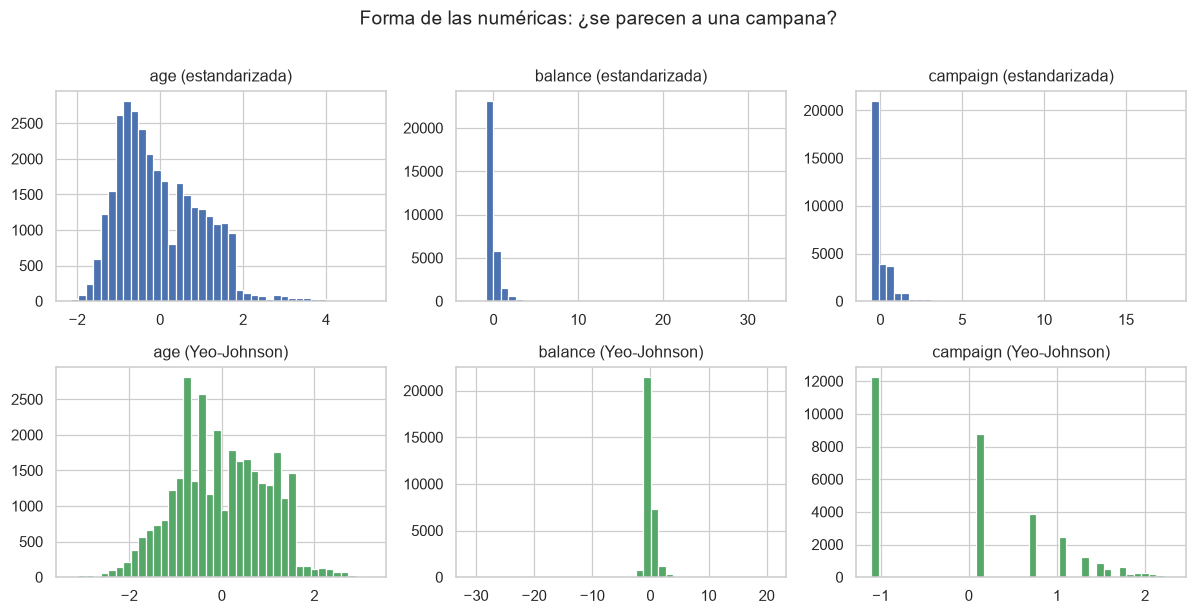

Figura guardada: figuras/fig_nb_forma_distribuciones.png


In [4]:
prep_estandar = clone(d.preprocesador).fit(d.X_train)
prep_yj = up.construir_preprocesador(d.cols_num, d.cols_cat, d.cols_bin, yeo_johnson=True).fit(d.X_train)

num_std = prep_estandar.transform(d.X_train)[d.cols_num]
num_yj = prep_yj.transform(d.X_train)[d.cols_num]

forma = pd.DataFrame({
    "asimetría (estandarizada)": num_std.apply(skew),
    "asimetría (Yeo-Johnson)": num_yj.apply(skew),
    "curtosis exceso (estandarizada)": num_std.apply(kurtosis),
    "curtosis exceso (Yeo-Johnson)": num_yj.apply(kurtosis),
}).round(2)
display(forma)
up.guardar_tabla(forma, "tabla_nb_forma_distribuciones")

n_total = prep_estandar.transform(d.X_train.head(5)).shape[1]
print(f"Columnas tras el preprocesamiento: {n_total} (de las cuales {len(d.cols_num)} son numéricas y "
      f"{n_total - len(d.cols_num)} son binarias 0/1)")

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for j, col in enumerate(["age", "balance", "campaign"]):
    axes[0, j].hist(num_std[col], bins=40, color="#4C72B0")
    axes[0, j].set_title(f"{col} (estandarizada)")
    axes[1, j].hist(num_yj[col], bins=40, color="#55A868")
    axes[1, j].set_title(f"{col} (Yeo-Johnson)")
fig.suptitle("Forma de las numéricas: ¿se parecen a una campana?", y=1.01)
fig.tight_layout()
plt.show()
up.guardar(fig, "fig_nb_forma_distribuciones")

### 2.4 Conclusión sobre los supuestos

- **Independencia condicional:** no se cumple en algunos pares. `pdays` y `previous` están casi perfectamente correlacionadas dentro de cada clase (0.99 en `no`), y `poutcome` con `pdays_contactado` tiene V de Cramér = 1: son la misma información contada dos veces. El resto de los pares tiene dependencia moderada (V ≤ 0.53; correlaciones ≤ 0.15).
- **Normalidad:** las numéricas con colas largas (`balance`, `previous`, `campaign`) están lejos de ser normales; Yeo-Johnson ayuda mucho en `campaign` y `age`, pero `balance`, `pdays` y `previous` siguen con colas pesadas por su gran masa en cero. Las columnas *one-hot* (0/1) tampoco son normales por construcción, lo que hace dudosa la variante Gaussiana.
- **Consecuencia esperada:** las probabilidades saldrán demasiado extremas (se cuenta dos veces la misma evidencia), pero el *ranking* de clientes suele aguantar mejor. Esto se comprueba en las secciones 7 y 8.

## 3. Variantes e hiperparámetros (espacio de búsqueda)

Como ninguna variante cumple perfectamente los supuestos, se comparan tres, todas dentro de un `Pipeline` (el preprocesamiento se ajusta dentro de cada fold) y con la **misma** validación cruzada de 5 folds sobre *train* y la misma métrica (AUC-PR):

| Variante | Qué hace | Supuesto que usa | Hiperparámetros buscados |
|---|---|---|---|
| **A · GaussianNB** | Numéricas estandarizadas + *one-hot* | Normal para todas las columnas (incluidas las 0/1, donde es claramente falso) | `var_smoothing`: 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 0.1, 0.3, 1 |
| **B · GaussianNB** | Igual que A, pero con Yeo-Johnson en las numéricas | Normal, con numéricas más simétricas | `var_smoothing`: los mismos 8 valores |
| **C · CategoricalNB** | Numéricas discretizadas en intervalos por cuantiles + categóricas codificadas como números enteros | Categórica para todas (no exige forma normal) | `alpha` (suavizado de Laplace): 0.1, 0.5, 1, 2, 5 y `n_bins` (intervalos por numérica): 3, 4, 5, 7, 10, 20 |

- `var_smoothing` suma una pequeña cantidad a las varianzas para evitar divisiones entre casi cero (importante con columnas *one-hot* de categorías raras).
- `alpha` evita probabilidades de cero para categorías que no aparecen con una clase.
- No se ajustan las probabilidades *a priori* de las clases: el desbalance se corrige después con el **umbral** elegido en validación.
- Total: 8 + 8 + 30 = 46 combinaciones × 5 folds = 230 ajustes (Naive Bayes ajusta en una fracción de segundo).

In [5]:
def construir_pipe_cat(cols_num, cols_cat, cols_bin, n_bins=10, alpha=1.0):
    # Variante C: numéricas -> intervalos por cuantiles; categóricas -> enteros; binarias -> sin cambio.
    categorias = [sorted(d.X_train[c].unique()) for c in cols_cat]   # vocabulario fijo (viene de train)
    # min_categories evita errores si un fold no contiene alguna categoría o intervalo
    min_cat = np.array([20] * len(cols_num) + [len(c) for c in categorias] + [2] * len(cols_bin))
    prep = ColumnTransformer([
        ("num", KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy="quantile"), cols_num),
        ("cat", OrdinalEncoder(categories=categorias), cols_cat),
        ("bin", "passthrough", cols_bin),
    ])
    return Pipeline([("prep", prep), ("modelo", CategoricalNB(alpha=alpha, min_categories=min_cat))])


pipe_A = Pipeline([("prep", clone(d.preprocesador)), ("modelo", GaussianNB())])
pipe_B = Pipeline([
    ("prep", up.construir_preprocesador(d.cols_num, d.cols_cat, d.cols_bin, yeo_johnson=True)),
    ("modelo", GaussianNB()),
])
pipe_C = construir_pipe_cat(d.cols_num, d.cols_cat, d.cols_bin)

espacio_gauss = {"modelo__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 0.3, 1.0]}
espacio_cat = {"prep__num__n_bins": [3, 4, 5, 7, 10, 20], "modelo__alpha": [0.1, 0.5, 1.0, 2.0, 5.0]}

variantes = {
    "A · GaussianNB (estandarizado + one-hot)": (pipe_A, espacio_gauss),
    "B · GaussianNB (Yeo-Johnson + one-hot)": (pipe_B, espacio_gauss),
    "C · CategoricalNB (numéricas discretizadas)": (pipe_C, espacio_cat),
}
nombre_A, nombre_B, nombre_C = list(variantes)

## 4. Búsqueda en malla con validación cruzada

Se ejecuta un `GridSearchCV` por variante (validación cruzada estratificada de 5 folds sobre *train*, métrica AUC-PR). Después se guarda la tabla de todas las combinaciones y se compara la mejor combinación de cada variante.

In [6]:
busquedas = {}
resumen = []
todas = []
for nombre, (pipe, espacio) in variantes.items():
    b = GridSearchCV(pipe, espacio, scoring=up.METRICA_CV, cv=up.CV, n_jobs=N_JOBS)
    b.fit(d.X_train, d.y_train)
    busquedas[nombre] = b

    r = b.cv_results_
    resumen.append({
        "variante": nombre,
        "mejores hiperparámetros": up.formatear_params(b.best_params_),
        "AUC-PR (CV) media": r["mean_test_score"][b.best_index_],
        "desv. estándar": r["std_test_score"][b.best_index_],
        "combinaciones": len(r["params"]),
    })
    todas.append(pd.DataFrame({
        "variante": nombre,
        "hiperparámetros": [up.formatear_params(p) for p in r["params"]],
        "AUC-PR (CV) media": r["mean_test_score"],
        "desv. estándar": r["std_test_score"],
        "ranking (dentro de la variante)": r["rank_test_score"],
    }))

tabla_variantes = pd.DataFrame(resumen).sort_values("AUC-PR (CV) media", ascending=False).reset_index(drop=True)
display(tabla_variantes.round(4))
up.guardar_tabla(tabla_variantes.round(4), "tabla_nb_variantes")
up.guardar_tabla(pd.concat(todas, ignore_index=True).round(4), "tabla_nb_busqueda_cv")

,variante,mejores hiperparámetros,AUC-PR (CV) media,desv. estándar,combinaciones
0,C · CategoricalNB (numéricas discretizadas),"alpha = 0.1, n_bins = 4",0.3860,0.016,30
1,B · GaussianNB (Yeo-Johnson + one-hot),var_smoothing = 0.01,0.3638,0.017,8
2,A · GaussianNB (estandarizado + one-hot),var_smoothing = 0.01,0.3502,0.025,8


Tabla guardada: resultados/tabla_nb_variantes.csv
Tabla guardada: resultados/tabla_nb_busqueda_cv.csv


Gráficas del efecto de cada hiperparámetro (con barras de desviación estándar entre folds) y comparación de las tres variantes.

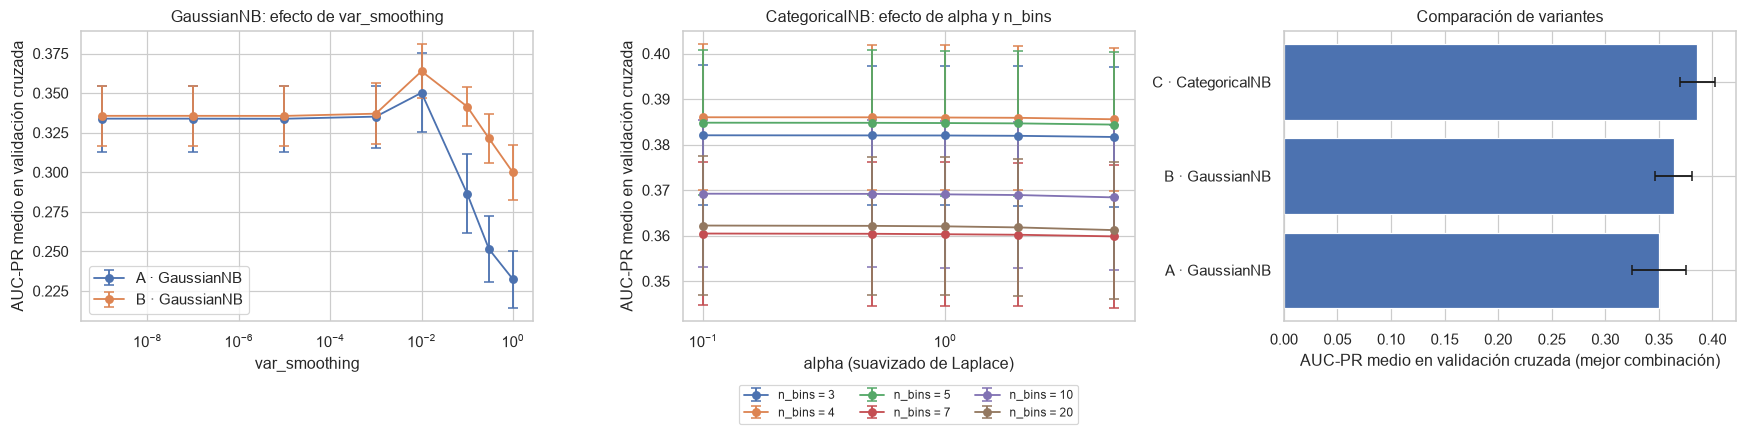

Figura guardada: figuras/fig_nb_busqueda_cv.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for nombre in (nombre_A, nombre_B):
    r = busquedas[nombre].cv_results_
    axes[0].errorbar([p["modelo__var_smoothing"] for p in r["params"]], r["mean_test_score"],
                     yerr=r["std_test_score"], marker="o", capsize=3, label=nombre.split(" (")[0])
axes[0].set_xscale("log")
axes[0].set_xlabel("var_smoothing")
axes[0].set_ylabel("AUC-PR medio en validación cruzada")
axes[0].set_title("GaussianNB: efecto de var_smoothing")
axes[0].legend()

r = busquedas[nombre_C].cv_results_
dfc = pd.DataFrame({"alpha": [p["modelo__alpha"] for p in r["params"]],
                    "n_bins": [p["prep__num__n_bins"] for p in r["params"]],
                    "media": r["mean_test_score"], "std": r["std_test_score"]})
for nb_, g in dfc.groupby("n_bins"):
    axes[1].errorbar(g["alpha"], g["media"], yerr=g["std"], marker="o", capsize=3, label=f"n_bins = {nb_}")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha (suavizado de Laplace)")
axes[1].set_ylabel("AUC-PR medio en validación cruzada")
axes[1].set_title("CategoricalNB: efecto de alpha y n_bins")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)

etiquetas = tabla_variantes["variante"].str.split(" (", regex=False).str[0].values[::-1]
axes[2].barh(etiquetas, tabla_variantes["AUC-PR (CV) media"].values[::-1],
             xerr=tabla_variantes["desv. estándar"].values[::-1], color="#4C72B0", capsize=3)
axes[2].set_xlabel("AUC-PR medio en validación cruzada (mejor combinación)")
axes[2].set_title("Comparación de variantes")

fig.tight_layout()
plt.show()
up.guardar(fig, "fig_nb_busqueda_cv")

### Elección de la variante

La variante final es la de **mayor AUC-PR medio en validación cruzada**. Si dos variantes quedan a menos de una desviación estándar de distancia, la diferencia no es real y conviene preferir la que mejor se justifique con los supuestos (sección 2). Si quieres forzar una variante, escribe su nombre exacto en `VARIANTE_FINAL`.

In [8]:
VARIANTE_FINAL = None      # ej.: VARIANTE_FINAL = nombre_C   (None = la mejor en validación cruzada)

if VARIANTE_FINAL is None:
    VARIANTE_FINAL = tabla_variantes.loc[0, "variante"]

mejor_nb = busquedas[VARIANTE_FINAL].best_estimator_
nombre_modelo = "Naive Bayes (" + VARIANTE_FINAL.split(" · ")[1].split(" (")[0] + ")"

print("Variante elegida:", VARIANTE_FINAL)
print("Hiperparámetros :", up.formatear_params(busquedas[VARIANTE_FINAL].best_params_))
print("Nombre en las tablas comparativas:", nombre_modelo)

Variante elegida: C · CategoricalNB (numéricas discretizadas)
Hiperparámetros : alpha = 0.1, n_bins = 4
Nombre en las tablas comparativas: Naive Bayes (CategoricalNB)


## 5. Evaluación de la variante elegida en el conjunto de prueba

`evaluar_modelo()` elige el umbral con el conjunto de **validación**, evalúa **una sola vez** en *test* y genera matriz de confusión, curva ROC y curva precisión-recall. También guarda en `resultados/` las métricas (`nb_metricas_test.json`) y las predicciones (`nb_predicciones_test.csv`) para la comparación final y el análisis de errores.

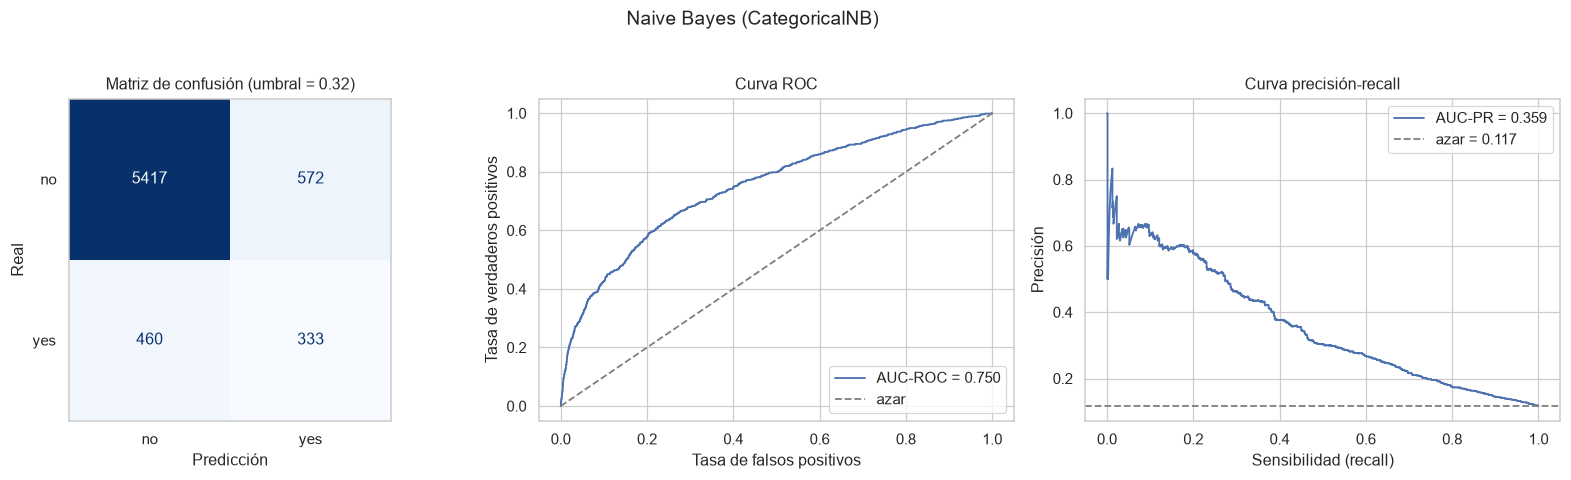

Figura guardada: figuras/fig_nb_evaluacion.png
Métricas guardadas: resultados/nb_metricas_test.json y resultados/nb_predicciones_test.csv


,test
umbral,0.3172
exactitud,0.8478
precisión,0.3680
sensibilidad,0.4199
F1,0.3922
AUC-ROC,0.7503
AUC-PR,0.3592


In [9]:
metricas_nb = up.evaluar_modelo(nombre_modelo, mejor_nb, "nb", d)
display(metricas_nb.to_frame("test"))

## 6. Variabilidad entre folds

Validación cruzada repetida 5 × 3 sobre *train* con el modelo elegido. Los puntajes por fold se guardan en `resultados/nb_cv_scores.csv` (se usarán para comparar modelos por pares).

In [10]:
tabla_var_nb = up.variabilidad_cv(nombre_modelo, mejor_nb, "nb", d, n_jobs=N_JOBS)
display(tabla_var_nb)

Tabla guardada: resultados/tabla_nb_variabilidad_cv.csv


,media,desv. estándar
AUC-PR,0.3861,0.0119
AUC-ROC,0.7554,0.0090


## 7. Experimento: ¿cuánto daña la redundancia entre variables?

Si la independencia condicional fuera un problema serio, **quitar variables redundantes** debería mejorar el modelo, porque dejaría de contar la misma evidencia dos veces. Se prueba con la variante C (la más fácil de ajustar a un subconjunto de columnas), usando los mejores hiperparámetros que encontró la búsqueda:

1. **Completo:** todas las variables.
2. **Sin `pdays_contactado`:** casi coincide con `poutcome = unknown` (ver 2.2).
3. **Sin `pdays_contactado` ni `pdays`:** además quita la numérica más correlacionada con `previous` (ver 2.1).

In [11]:
mejores_C = busquedas[nombre_C].best_params_
n_bins_C = mejores_C["prep__num__n_bins"]
alpha_C = mejores_C["modelo__alpha"]

configuraciones = {
    "completo": (d.cols_num, d.cols_cat, d.cols_bin),
    "sin pdays_contactado": (d.cols_num, d.cols_cat, []),
    "sin pdays_contactado ni pdays": ([c for c in d.cols_num if c != "pdays"], d.cols_cat, []),
}

filas = []
for nombre, (cn, cc, cb) in configuraciones.items():
    pipe = construir_pipe_cat(cn, cc, cb, n_bins=n_bins_C, alpha=alpha_C)
    r = cross_validate(pipe, d.X_train[cn + cc + cb], d.y_train, cv=up.CV, scoring=up.METRICA_CV, n_jobs=N_JOBS)
    filas.append({"configuración": nombre, "variables": len(cn + cc + cb),
                  "AUC-PR (CV) media": r["test_score"].mean(), "desv. estándar": r["test_score"].std()})

tabla_redundancia = pd.DataFrame(filas)
display(tabla_redundancia.round(4))
up.guardar_tabla(tabla_redundancia.round(4), "tabla_nb_experimento_redundancia")

,configuración,variables,AUC-PR (CV) media,desv. estándar
0,completo,16,0.3860,0.0160
1,sin pdays_contactado,15,0.3912,0.0142
2,sin pdays_contactado ni pdays,14,0.3912,0.0142


Tabla guardada: resultados/tabla_nb_experimento_redundancia.csv


## 8. Calibración de las probabilidades

Los supuestos de la sección 2 anticipaban que las probabilidades de Naive Bayes saldrían demasiado extremas. Se comprueba agrupando a los clientes de *test* por la probabilidad que predijo el modelo y comparándola con la proporción real de `yes` en cada grupo.

In [12]:
pred_nb = pd.read_csv(up.RESULTADOS / "nb_predicciones_test.csv")
grupos = pd.cut(pred_nb["proba"], [0, 0.01, 0.05, 0.2, 0.5, 0.9, 1.0], include_lowest=True)
tabla_calibracion = (pred_nb.groupby(grupos, observed=True)
                     .agg(clientes=("proba", "size"),
                          proba_media_predicha=("proba", "mean"),
                          proporcion_real_yes=("y_real", "mean"))
                     .round(3))
tabla_calibracion.index = tabla_calibracion.index.astype(str)
display(tabla_calibracion)
up.guardar_tabla(tabla_calibracion, "tabla_nb_calibracion")

,clientes,proba_media_predicha,proporcion_real_yes
proba,,,
"(-0.001, 0.01]",1208,0.005,0.035
"(0.01, 0.05]",2044,0.026,0.058
"(0.05, 0.2]",2084,0.106,0.100
"(0.2, 0.5]",872,0.305,0.193
"(0.5, 0.9]",378,0.678,0.370
"(0.9, 1.0]",196,0.956,0.592


Tabla guardada: resultados/tabla_nb_calibracion.csv


## 9. Interpretación

_Los números de abajo son los de la corrida con semilla 42 y los datos de la Parte 1. Si tu tabla da valores distintos, actualiza el texto con los tuyos._

**Supuestos (sección 2).** La independencia condicional no se cumple en pares concretos: `pdays` y `previous` tienen una correlación de 0.99 dentro de la clase `no` (0.93 en `yes`) y `poutcome` con `pdays_contactado` tiene una V de Cramér de 1.00, porque ambas dicen prácticamente lo mismo (que el cliente no fue contactado antes). Fuera de esos pares la dependencia es moderada (V ≤ 0.53; correlaciones ≤ 0.15). Las numéricas están lejos de ser normales: `balance` tiene asimetría 8.3 y `previous` 7.7; Yeo-Johnson corrige bien `campaign` (4.9 → 0.2) y `age`, pero deja `balance` (1.4 de asimetría y curtosis 68) y `pdays`/`previous` (1.65) con colas pesadas, porque tienen una gran masa en cero.

**Variantes (sección 4).** La mejor fue **CategoricalNB** con `alpha = 0.1` y `n_bins = 4` (AUC-PR en CV 0.386), por delante de GaussianNB con Yeo-Johnson (0.364) y de GaussianNB estandarizado (0.350). Tiene sentido: discretizar evita suponer normalidad y capta relaciones no lineales con `age` o `balance` (por ejemplo, la tasa de `yes` forma una U con la edad: 26 % en menores de 25 años, 9–11 % entre 30 y 59 y 30–42 % a partir de los 60). Las tres variantes quedan dentro de unas pocas desviaciones estándar entre folds (≈ 0.016–0.025), así que la ventaja de C es real pero modesta. `alpha` casi no influye (la diferencia entre 0.1 y 5 es menor que 0.001) porque casi todas las categorías e intervalos tienen cientos o miles de ejemplos en cada clase y el suavizado solo importa en las pocas categorías raras; lo que sí influye es `n_bins`: menos intervalos funcionan mejor (3–5 intervalos > 7 > 10 > 20), porque con muchos intervalos cada uno aporta una estimación ruidosa y, al multiplicar 16 factores, ese ruido se acumula. El óptimo (4) queda dentro de la malla (el 3 es peor), y en `var_smoothing` el óptimo es 0.01, también interior.

**Resultado en test.** Con umbral 0.32 (elegido en validación): AUC-PR 0.359, AUC-ROC 0.750, F1 0.392, precisión 0.368 y sensibilidad 0.420. Es **peor que el modelo de referencia** (regresión logística: AUC-PR 0.381, AUC-ROC 0.759, F1 0.431): Naive Bayes tiene sentido como línea base probabilística sencilla, pero no supera a un modelo que sí pondera las variables conjuntamente. En test el AUC-PR (0.359) quedó algo por debajo del de CV (0.386); la diferencia es de ≈ 2 desviaciones entre folds y es compatible con la variación de una sola muestra de 6,782 clientes (793 `yes`), no con un sobreajuste (el modelo casi no tiene hiperparámetros que sobreajustar).

**Redundancia (sección 7).** Quitar `pdays_contactado` sube el AUC-PR en CV de 0.386 a 0.391 y quitar también `pdays` no cambia nada más (esa columna ya no aportaba al discretizar). La mejora (+0.005) es menor que la desviación entre folds (≈ 0.015): va en la dirección esperada (menos evidencia contada dos veces), pero es pequeña y no concluyente. El *ranking* de clientes resiste bien la violación de la independencia; lo que sufre es la probabilidad (siguiente punto).

**Calibración (sección 8).** Las probabilidades están mal calibradas por los mismos supuestos: entre los clientes a los que el modelo les da más de 0.9 (196 clientes, probabilidad media 0.96) solo contrata el 59 %; en el tramo 0.5–0.9 el modelo predice 0.68 y la realidad es 0.37. También falla por abajo: en el tramo menor a 0.01 contrata el 3.5 %, no el 0.5 %. Por eso el **umbral se elige en validación** (0.32) en lugar de usar 0.5, y por eso las probabilidades de este modelo sirven para ordenar clientes pero no para interpretarse como probabilidades reales. Si se necesitaran probabilidades confiables habría que recalibrar (regresión isotónica o de Platt, `CalibratedClassifierCV`).